# Estatística sobre o agente (AO1 da D3)

Rodar de cima para baixo com o kernel do `.venv`. Respostas nos campos **R:**.

> **Escopo:** itens 1 e 2 do enunciado. Por orientação do professor, o intervalo de confiança, o tamanho de amostra (item 3) e a correlação/causalidade (item 4) ficam para a N2. As seções finais estão vazias de propósito.
>
> **Local:** tudo em `D03/AO1/` (notebook, `ao1.py`, `acertos.csv`, `dados/`).

- Conjunto: R: `dados/casos-60.csv`, com 60 casos rotulados por mim (não usei o `casos-ams-60.csv` do professor).
- De onde vieram os casos novos: R: A01–A30 são os 30 casos reais do AI4I usados na D2, adaptados ao esquema da D3. B01–B30 são 30 casos novos do AI4I, fáceis e difíceis, sem repetir UDI. Procedência em `dados/FONTE.md`.
- A: linha de base da D2 (`decidir()` de `src/ams/baseline.py`). B: R: **passo de verificação antes de parar.**
  - A A para com uma única evidência (vibração > 7,0 mm/s ou desgaste ≥ 150 h).
  - A B conta três evidências: vibração > 7,0 mm/s, desgaste ≥ 150 h e 1 ou mais falhas recentes da família.
  - 2 ou mais evidências → parar; 1 → inspecionar; 0 → seguir.
  - Mudanças em relação à A: (1) a regra de confirmação e (2) o corte do histórico, que passou de 2 falhas para 1.
  - Inspecionar também exige LOTO (NR-12). A B é experimental.

In [1]:
%run ao1.py

60 casos
A acertou 35 · B acertou 26
decisões diferentes entre A e B: 26
discordam no A02 · A: 0 · B: 1
discordam no A03 · A: 1 · B: 0
discordam no A13 · A: 0 · B: 1
discordam no A14 · A: 1 · B: 0
discordam no A22 · A: 1 · B: 0
discordam no A24 · A: 1 · B: 0
discordam no A26 · A: 1 · B: 0
discordam no A29 · A: 1 · B: 0
discordam no B23 · A: 1 · B: 0
discordam no B13 · A: 1 · B: 0
discordam no B17 · A: 1 · B: 0
discordam no B02 · A: 1 · B: 0
discordam no B21 · A: 1 · B: 0
discordam no B19 · A: 1 · B: 0
discordam no B03 · A: 0 · B: 1
discordam no B11 · A: 1 · B: 0
discordam no B24 · A: 1 · B: 0
discordam no B07 · A: 0 · B: 1
discordam no B04 · A: 0 · B: 1
latência A (µs) em 3000 decisões: p50 0.5 · p95 0.9 · média 0.46 · máximo 14.5
latência B (µs) em 3000 decisões: p50 1.0 · p95 2.0 · média 1.13 · máximo 14.3


In [2]:
# Pareamento: os quatro quadrantes de acerto (A, B) sobre os MESMOS 60 casos
import pandas as pd

acertos = pd.read_csv(ARQUIVO_DE_ACERTOS)
print(pd.crosstab(acertos["linha_de_base"], acertos["variante_b"],
                  rownames=["A acertou"], colnames=["B acertou"], margins=True))

so_a = int(((acertos.linha_de_base == 1) & (acertos.variante_b == 0)).sum())
so_b = int(((acertos.linha_de_base == 0) & (acertos.variante_b == 1)).sum())
print(f"\nacerto geral: A = {acertos.linha_de_base.mean():.3f} · B = {acertos.variante_b.mean():.3f}")
print(f"discordantes: {so_a + so_b} (só A acertou: {so_a} · só B acertou: {so_b})")

# Em que tipo de caso a B muda a decisão da A
comparacao = pd.DataFrame({
    "id_caso": [c["id_caso"] for c in casos],
    "correta": [c["acao_correta"] for c in casos],
    "A": decisoes_a,
    "B": decisoes_b,
})
mudou = comparacao[comparacao.A != comparacao.B]
print(f"\ndecisões diferentes: {len(mudou)}")
print(pd.crosstab(mudou.A, mudou.B, rownames=["A decidiu"], colnames=["B decidiu"]))

# As 14 perdas da B (A acertou, B errou), separadas pelo que a A tinha decidido
perdas = comparacao[(comparacao.A == comparacao.correta) & (comparacao.B != comparacao.correta)]
print("\nperdas da B, pelo que a A decidiu (e acertou):")
for decisao_a, grupo in perdas.groupby("A"):
    print(f"  {decisao_a}: {len(grupo)} → {', '.join(grupo.id_caso)}")

# As métricas da §4 do agent-spec.md, para as duas variantes
PARAR, SEGUIR = "parar_para_manutencao", "seguir_operando"
reais_alto = (comparacao.correta == PARAR).sum()
linhas = {}
for nome in ["A", "B"]:
    d = comparacao[nome]
    linhas[nome] = {
        "acerto geral (primária)": f"{(d == comparacao.correta).sum()}/60",
        "recall alto (sec. 1, meta ≥ 80%)": f"{((d == PARAR) & (comparacao.correta == PARAR)).sum()}/{reais_alto}",
        "precisão alto (sec. 2, meta ≥ 80%)": f"{((d == PARAR) & (comparacao.correta == PARAR)).sum()}/{(d == PARAR).sum()}",
        "alto decidido como baixo (sec. 3, meta ≤ 5%)": f"{((d == SEGUIR) & (comparacao.correta == PARAR)).sum()}/{reais_alto}",
    }
print()
print(pd.DataFrame(linhas))

# Acerto da A por metade do conjunto (A01–A30 = casos da D2; B01–B30 = novos)
metade = comparacao.id_caso.str[0]
print("\nacerto por metade:")
print(pd.DataFrame({n: (comparacao[n] == comparacao.correta).groupby(metade).sum() for n in ["A", "B"]}))

B acertou   0   1  All
A acertou             
0          20   5   25
1          14  21   35
All        34  26   60

acerto geral: A = 0.583 · B = 0.433
discordantes: 19 (só A acertou: 14 · só B acertou: 5)

decisões diferentes: 26
B decidiu              inspecionar_antes_de_operar
A decidiu                                         
parar_para_manutencao                           16
seguir_operando                                 10

perdas da B, pelo que a A decidiu (e acertou):
  parar_para_manutencao: 8 → A03, A14, A22, A24, A29, B13, B02, B11
  seguir_operando: 6 → A26, B23, B17, B21, B19, B24

                                                  A      B
acerto geral (primária)                       35/60  26/60
recall alto (sec. 1, meta ≥ 80%)              10/16   2/16
precisão alto (sec. 2, meta ≥ 80%)            10/23    2/7
alto decidido como baixo (sec. 3, meta ≤ 5%)   5/16   1/16

acerto por metade:
          A   B
id_caso        
A        19  15
B        16  11


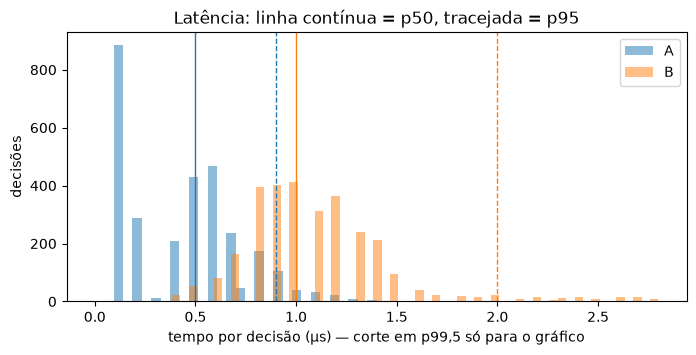

,A,B
p50,0.50,1.00
p95,0.90,2.00
média,0.46,1.13
máximo,14.50,14.30
média / p50,0.92,1.13


In [3]:
# Latência: distribuição dos tempos de decisão (50 rodadas × 60 casos por variante)
import matplotlib.pyplot as plt

fig, eixo = plt.subplots(figsize=(8, 3.5))
limite = np.percentile(np.concatenate([tempos_a, tempos_b]), 99.5)
for nome, t in [("A", tempos_a), ("B", tempos_b)]:
    eixo.hist(t[t <= limite], bins=60, alpha=0.5, label=nome)
    for q, estilo in [(50, "-"), (95, "--")]:
        eixo.axvline(np.percentile(t, q), linestyle=estilo, linewidth=1,
                     color="C0" if nome == "A" else "C1")
eixo.set_xlabel("tempo por decisão (µs) — corte em p99,5 só para o gráfico")
eixo.set_ylabel("decisões")
eixo.set_title("Latência: linha contínua = p50, tracejada = p95")
eixo.legend()
plt.show()

pd.DataFrame({nome: {"p50": np.percentile(t, 50), "p95": np.percentile(t, 95),
                     "média": t.mean(), "máximo": t.max(),
                     "média / p50": t.mean() / np.percentile(t, 50)}
              for nome, t in [("A", tempos_a), ("B", tempos_b)]}).round(2)

## As duas variantes e a latência

**Pareamento (acertos de cada variante, em quantos casos discordam e a favor de quem):** R:
- A acerta **35/60 (58%)** e a B acerta **26/60 (43%)**.
- Discordam em **19 casos: 14 a favor da A e 5 a favor da B**.
- Todas as 26 decisões que a B muda viram "inspecionar".
- A B ganha em 5 casos, em que a A parava com um sinal isolado.
- A B perde em 14: 8 falhas reais rebaixadas para inspecionar e 6 falsos alarmes causados pelo histórico.
- Pelas métricas da §4 (tabela acima), a B piora o recall da classe "alto" (10/16 → 2/16), mas reduz os casos de risco alto liberados como "seguir" (5/16 → 1/16). Nenhuma das duas atinge as metas.
- A diferença de 15 pp ainda precisa do teste pareado (D3-06, N2). Por enquanto: **não sei ainda**.
- Ressalva: a A foi calibrada nos casos A01–A30 e a B foi pensada olhando estes 60 casos, então as duas podem estar otimistas.
- A A acerta 19/30 nos casos da D2, contra 21/30 na D2, porque a família de máquina foi sorteada de novo (erros novos em A15 e A21).

**Latência (p50 e p95, e por que a média engana em tempo de resposta):** R:
- São 3.000 decisões por variante. p50 e p95 ficam na casa de 1 µs a poucos µs; os valores exatos estão na tabela e mudam a cada execução.
- A diferença entre A e B está na resolução do relógio (cerca de 0,1 µs).
- Tempo de resposta tem cauda longa: poucas chamadas lentas puxam a média para cima. O p50 mostra o caso típico, e o p95 o pior caso frequente (1 em 20).
- Neste agente de regras a média fica perto do p50. A diferença pesa de verdade no agente com LLM (D10).

In [4]:
# O medidas.py só protege as decisões escritas quando a saída se chama
# relatorio-dado.md; com --saida relatorio-60.md ele SOBRESCREVE. Por isso só
# gera o relatório se ele ainda não existir; as decisões ficam preservadas.
import sys
from pathlib import Path
if not Path("relatorio-60.md").exists():
    !"{sys.executable}" ../D3-03-estatistica-descritiva/medidas.py dados/casos-60.csv --saida relatorio-60.md
from IPython.display import Markdown
Markdown(open("relatorio-60.md", encoding="utf-8").read())

# O meu dado, com rigor — relatório do Laboratório 03

Conjunto: `dados\casos-60.csv` · 60 linhas · 11 variáveis

Medidas geradas pelo `medidas.py`: desvio padrão amostral (ddof=1),
quartis por interpolação linear, extremos pela regra da amplitude
interquartil — fora de 1,5 × a caixa (slide 24). As medidas são do
programa; as decisões são SUAS. Preencha todos os blocos `R:` e
confira com `python teste.py`.

## Medidas por variável

| variável | tipo | n | faltantes | média | mediana | desvio | Q1 | Q3 | AIQ | mín | máx |
|---|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| id_caso | categórica (60 valores; moda: B30) | 60 | 0 | — | — | — | — | — | — | — | — |
| data | categórica (60 valores; moda: 2026-04-01) | 60 | 0 | — | — | — | — | — | — | — | — |
| tipo_maquina | categórica (4 valores; moda: ROBOT) | 60 | 0 | — | — | — | — | — | — | — | — |
| qualidade_produto | categórica (3 valores; moda: L) | 60 | 0 | — | — | — | — | — | — | — | — |
| temperatura_c | numérica | 60 | 0 | 36.7033 | 36.8500 | 1.5445 | 35.4250 | 37.8250 | 2.4000 | 33.4000 | 39.9000 |
| vibracao_mm_s | numérica | 60 | 0 | 3.8367 | 3.4000 | 1.9182 | 2.4750 | 4.5000 | 2.0250 | 2.1000 | 11.3000 |
| horas_desde_manutencao | numérica | 60 | 0 | 110.1833 | 100.0000 | 70.1771 | 52.2500 | 170.7500 | 118.5000 | 0.0000 | 240.0000 |
| acao_correta | categórica (3 valores; moda: seguir_operando) | 60 | 0 | — | — | — | — | — | — | — | — |
| falhou_depois | numérica | 60 | 0 | 0.2667 | 0.0000 | 0.4459 | 0.0000 | 1.0000 | 1.0000 | 0.0000 | 1.0000 |
| risco | categórica (3 valores; moda: baixo) | 60 | 0 | — | — | — | — | — | — | — | — |
| dificuldade | categórica (3 valores; moda: facil) | 60 | 0 | — | — | — | — | — | — | — | — |

## Extremos marcados (fora de 1,5 × a caixa — slide 24)

### Extremos de `vibracao_mm_s` — 4 valor(es), limites [-0.5625; 7.5375]

| linha | valor |
|---:|---:|
| 8 | 9.2000 |
| 14 | 11.3000 |
| 34 | 9.7000 |
| 41 | 9.7000 |

Decisão sobre ESTES extremos — manter ou remover, caso a caso,
com o motivo (slide 25: quem remove sem dizer, mente por omissão):

R: Ficam os 4. Não são erro: o proxy de vibração sai da mesma fórmula sobre RPM e torque reais. A14 e B11 são falhas reais; A08 e B04 são casos difíceis rotulados inspecionar. Se saíssem: n = 56, média de vibração 3,84 → 3,40, mediana 3,40 → 3,35, e a classe parar perderia 2 dos 16 casos.


## Faltantes (os três mecanismos do slide 26)

Nenhuma variável tem valores faltantes.

## As quatro perguntas do slide 29

**1. Média e mediana se separam em alguma variável? Em qual?**

R: Sim, em `vibracao_mm_s`: média 3,84 contra mediana 3,40, por causa dos 4 extremos. Em temperatura (36,70 × 36,85) e horas (110 × 100), as duas ficam próximas.

**2. Quantos extremos foram marcados, e quantos você decidiu manter?**

R: 4 extremos, todos em vibração (A08, A14, B04, B11), e mantive os 4.

**3. Algum faltante parece do terceiro mecanismo?**

R: Não. Há 0 faltantes, porque o AI4I é completo. Em ordens de serviço reais, o caso provável seria a leitura que falta justamente na máquina com defeito, e essas linhas não poderiam ser descartadas.

**4. O que a análise da D1 não tinha visto?**

R: (1) O conjunto é desbalanceado: responder sempre "seguir" acerta 53%. (2) `falhou_depois` coincide 100% com a classe parar: é o desfecho, não entrada. (3) Os extremos aparecem agora no proxy de vibração, e metade deles não são falhas.

## Comparação com a análise exploratória da D1

O que mudou de lá para cá — o que a análise de lá não tinha visto,
e o que estas decisões escritas mudam no conjunto que a D5 vai usar:

R: A avaliação usa 60 casos escolhidos, não a base inteira da D1: 27% de falhas contra cerca de 3,4% na base. Por isso o acerto geral precisa vir com o recall da classe alto, e as variantes são comparadas nos mesmos 60 casos. Nada foi removido nem imputado.


## Decisões

**Distribuições das variáveis relevantes:** R:
- Classes: seguir 32, parar 16, inspecionar 12. Responder sempre "seguir" já acertaria 53%, então o acerto geral precisa vir junto com o recall da classe "alto".
- `falhou_depois` é 1 exatamente nos 16 casos "parar". É o desfecho, não pode ser entrada do agente.
- `temperatura_c`: simétrica e estreita (33,4 a 39,9 °C), sem extremos.
- `vibracao_mm_s`: proxy de RPM e torque, assimétrica à direita (média 3,84 > mediana 3,40).
- `horas_desde_manutencao`: de 0 a 240 h, média 110 e mediana 100, sem extremos.

**Extremos (para cada variável: ficam ou saem, por quê, e o que muda):** R:
- Só a vibração tem extremos: A08 (9,2), A14 (11,3), B04 (9,7) e B11 (9,7).
- **Ficam os quatro.** Não são erro: dois são falhas reais e dois são casos difíceis rotulados "inspecionar".
- Se saíssem, a média da vibração cairia de 3,84 para 3,40, a mediana quase não mudaria (3,35) e a classe "parar" perderia 2 dos 16 casos.

**Faltantes (o mecanismo provável: perdido ao acaso, perdido condicionalmente ou perdido por causa do próprio valor, e o que ele autoriza; ou "não há"):** R:
- **Não há**: zero faltantes, porque o AI4I é completo e os casos vieram de linhas completas.
- Em OS reais, o faltante provável seria MNAR (a leitura falta justamente na máquina com defeito). Isso proibiria descartar essas linhas.

## Intervalo por reamostragem (depois do E3, entregue com a N2)

## Tamanho de amostra (depois do E3, entregue com a N2)

## Correlação e causalidade (depois do E4, entregue com a N2)

## Comparação pareada (depois do E4, anexo da N2)